In [2]:
from itertools import chain
from collections import defaultdict
from torch.utils.data import Subset
from torchvision import datasets

def subset_sampler(dataset, classes, max_len):
    # 1, 2번 수정: target_idx 선언 오타 수정 및 enumerate 올바르게 수정
    target_idx = defaultdict(list)
    for idx, (_, label) in enumerate(dataset):
        target_idx[int(label)].append(idx)

    # 3번 수정: 깔끔한 리스트 컴프리헨션
    indices = list(
        chain.from_iterable(
            [target_idx[idx][:max_len] for idx in range(len(classes))]
        )
    )
    return Subset(dataset, indices)

# 데이터셋 다운로드
train_dataset = datasets.FashionMNIST(root="./datasets", download=True, train=True)
test_dataset = datasets.FashionMNIST(root="./datasets", download=True, train=False)

classes = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

print("Classes:", classes)
print("Class to Index:", class_to_idx)

# Train 및 Test Subset 생성
subset_train_dataset = subset_sampler(
    dataset=train_dataset, classes=train_dataset.classes, max_len=100
)
# 4번 수정: 테스트 셋에도 샘플러 적용
subset_test_dataset = subset_sampler(
    dataset=test_dataset, classes=test_dataset.classes, max_len=100
)

print(f"Training Data Size: {len(subset_train_dataset)}")
print(f"Testing Data Size: {len(subset_test_dataset)}")
print("First train data sample (Image tensor, Label):", train_dataset[0])

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 306kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.58MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.4MB/s]


Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Class to Index: {'T-shirt/top': 0, 'Trouser': 1, 'Pullover': 2, 'Dress': 3, 'Coat': 4, 'Sandal': 5, 'Shirt': 6, 'Sneaker': 7, 'Bag': 8, 'Ankle boot': 9}
Training Data Size: 1000
Testing Data Size: 1000
First train data sample (Image tensor, Label): (<PIL.Image.Image image mode=L size=28x28 at 0x7D096B17D7D0>, 9)


In [3]:
# 10.2 이미지 전처리
import torch
from torchvision import transforms
from transformers import AutoImageProcessor

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path = "google/vit-base-patch16-224-in21k"
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(
            size = (
                image_processor.size["height"],
                image_processor.size["width"]
            )
        ),
        transforms.Lambda(
            lambda x: torch.cat([x, x, x], 0)
        ),
        transforms.Normalize(
            mean = image_processor.image_mean,
            std = image_processor.image_std
        )
    ]
)

print(f"size: {image_processor.size}")
print(f"mean: {image_processor.image_mean}")
print(f"std: {image_processor.image_std}")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

size: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
mean: (0.5, 0.5, 0.5)
std: (0.5, 0.5, 0.5)


In [4]:
# 10.3 VIT 데이터로더 적용
from torch.utils.data import DataLoader

def collator(data, transform):
  images, labels = zip(*data)
  pixel_values = torch.stack([transform(image) for image in images])
  labels = torch.tensor([label for label in labels])
  return {"pixel_values": pixel_values, "labels": labels}

train_dataloader = DataLoader(
    subset_train_dataset,
    batch_size = 32,
    shuffle = True,
    collate_fn = lambda x: collator(x, transform),
    drop_last = True
)
valid_dataloader = DataLoader(
    subset_test_dataset,
    batch_size = 4,
    shuffle = True,
    collate_fn = lambda x: collator(x, transform),
    drop_last = True
)

batch = next(iter(train_dataloader))
for key, value in batch.items():
  print(f"{key}: {value.shape}")

pixel_values: torch.Size([32, 3, 224, 224])
labels: torch.Size([32])


In [5]:
# 예제 10.4 사전 학습된 VIT 모델
from transformers import ViTForImageClassification

model = ViTForImageClassification.from_pretrained(
    pretrained_model_name_or_path = "google/vit-base-patch16-224-in21k",
    num_labels = len(classes),
    id2label = {i: label for i, label in enumerate(classes)},
    label2id = class_to_idx,
    ignore_mismatched_sizes = True
)

print(model.classifier)

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=10, bias=True)


In [6]:
# 예제 10.5 패치 임베딩 확인
print(model.vit.embeddings)

batch = next(iter(train_dataloader))
print("image shape:", batch["pixel_values"].shape)
print("patch embeddings shape:",
      model.vit.embeddings.patch_embeddings(batch["pixel_values"]).shape
)
print("[CLS] + patch embeddings shape: ",
      model.vit.embeddings(batch["pixel_values"]).shape
      )

ViTEmbeddings(
  (patch_embeddings): ViTPatchEmbeddings(
    (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  )
  (dropout): Dropout(p=0.0, inplace=False)
)
image shape: torch.Size([32, 3, 224, 224])
patch embeddings shape: torch.Size([32, 196, 768])
[CLS] + patch embeddings shape:  torch.Size([32, 197, 768])


In [7]:
#10.6 하이퍼파라미터 설정
from transformers import TrainingArguments
args = TrainingArguments(
    output_dir = "../models/ViT-FashionMNIST",
    save_strategy = "epoch",
    eval_strategy = "epoch",
    learning_rate = 1e-5,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size = 16,
    num_train_epochs = 3,
    weight_decay = 0.001,
    load_best_model_at_end = True,
    metric_for_best_model = "f1",
    #logging_dir="logs",
    logging_steps=125,
    remove_unused_columns=False,
    seed = 7
)

In [8]:
!pip install evaluate

In [9]:
#10.7 매크로 평균 F1 점수
import evaluate
import numpy as np

def compute_metrics(eval_pred):
  metric = evaluate.load("f1")
  predictions, labels = eval_pred
  predictions = np.argmax(predictions, axis=1)
  macro_f1 = metric.compute(
      predictions = predictions,
      references = labels,
      average = "macro"
  )
  return macro_f1


In [10]:
# 10.8 VIT 모델 학습
import torch
import evaluate
import numpy as np
from itertools import chain
from collections import defaultdict
from torch.utils.data import Subset
from torchvision import datasets
from torchvision import transforms
from transformers import AutoImageProcessor
from transformers import ViTForImageClassification
from transformers import TrainingArguments
from transformers import Trainer


def subset_sampler(dataset, classes, max_len):
    target_idx = defaultdict(list)
    for idx, label in enumerate(dataset.targets):
        target_idx[int(label)].append(idx)

    indices = list(
        chain.from_iterable(
            [target_idx[idx][:max_len] for idx in range(len(classes))]
        )
    )
    return Subset(dataset, indices)


def model_init(classes, class_to_idx):
    model = ViTForImageClassification.from_pretrained(
        pretrained_model_name_or_path="google/vit-base-patch16-224-in21k",
        num_labels=len(classes),
        id2label={idx: label for label, idx in class_to_idx.items()},
        label2id=class_to_idx,
    )
    return model


def collator(data, transform):
    images, labels = zip(*data)
    pixel_values = torch.stack([transform(image) for image in images])
    labels = torch.tensor([label for label in labels])
    return {"pixel_values": pixel_values, "labels": labels}


def compute_metrics(eval_pred):
    metric = evaluate.load("f1")
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    macro_f1 = metric.compute(
        predictions=predictions,
        references=labels,
        average="macro",
    )
    return macro_f1


train_dataset = datasets.FashionMNIST(
    root="../datasets", download=True, train=True
)
test_dataset = datasets.FashionMNIST(
    root="../datasets", download=True, train=False
)

classes = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

subset_train_dataset = subset_sampler(
    dataset=train_dataset, classes=train_dataset.classes, max_len=1000
)
subset_test_dataset = subset_sampler(
    dataset=test_dataset, classes=test_dataset.classes, max_len=1000
)

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path="google/vit-base-patch16-224-in21k"
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(
            size=(
                image_processor.size["height"],
                image_processor.size["width"],
            )
        ),
        transforms.Lambda(
            lambda x: torch.cat([x, x, x], 0)
        ),
        transforms.Normalize(
            mean=image_processor.image_mean,
            std=image_processor.image_std
        ),
    ]
)

args = TrainingArguments(
    output_dir = "../models/ViT-FashionMNIST",
    save_strategy = "epoch",
    eval_strategy = "epoch",
    learning_rate = 1e-5,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size = 16,
    num_train_epochs = 3,
    weight_decay = 0.001,
    load_best_model_at_end = True,
    metric_for_best_model = "f1",
    remove_unused_columns=False,
    seed = 7
)

trainer = Trainer(
    model_init=lambda _: model_init(classes, class_to_idx),
    args=args,
    train_dataset=subset_train_dataset,
    eval_dataset=subset_test_dataset,
    data_collator=lambda x: collator(x, transform),
    compute_metrics=compute_metrics,
    processing_class=image_processor,
)
trainer.train()

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 305kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.64MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.1MB/s]


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,F1
1,1.251111,0.677000,0.868476
2,0.623007,0.514813,0.895779
3,0.478637,0.464882,0.910155


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 'vit.layers.1.attention.o_proj.bias', 'vit.layers.1.layernorm_before

TrainOutput(global_step=1875, training_loss=0.713131884765625, metrics={'train_runtime': 1572.1947, 'train_samples_per_second': 19.082, 'train_steps_per_second': 1.193, 'total_flos': 2.32492637712384e+18, 'train_loss': 0.713131884765625, 'epoch': 3.0})

PredictionOutput(predictions=array([[ 3.0089104 , -0.559255  , -0.43296748, ..., -0.4764979 ,
        -0.5261559 , -0.3977015 ],
       [ 1.7357038 , -0.6682248 , -0.21808976, ..., -0.7420527 ,
        -0.6749277 , -0.6217171 ],
       [ 2.9272852 , -0.55292356, -0.41689375, ..., -0.38307342,
        -0.5676694 , -0.44895586],
       ...,
       [-0.3906215 , -0.6064086 , -0.55769336, ...,  0.06467411,
        -0.39064178,  3.2466223 ],
       [-0.30046472, -0.59857476, -0.56291115, ..., -0.270754  ,
        -0.34894416,  3.2397883 ],
       [-0.302659  , -0.6160082 , -0.5550165 , ..., -0.21153657,
        -0.40858656,  3.2354145 ]], dtype=float32), label_ids=array([0, 0, 0, ..., 9, 9, 9]), metrics={'test_loss': 0.46488216519355774, 'test_f1': 0.9101551785941021, 'test_runtime': 133.5673, 'test_samples_per_second': 74.869, 'test_steps_per_second': 4.679})


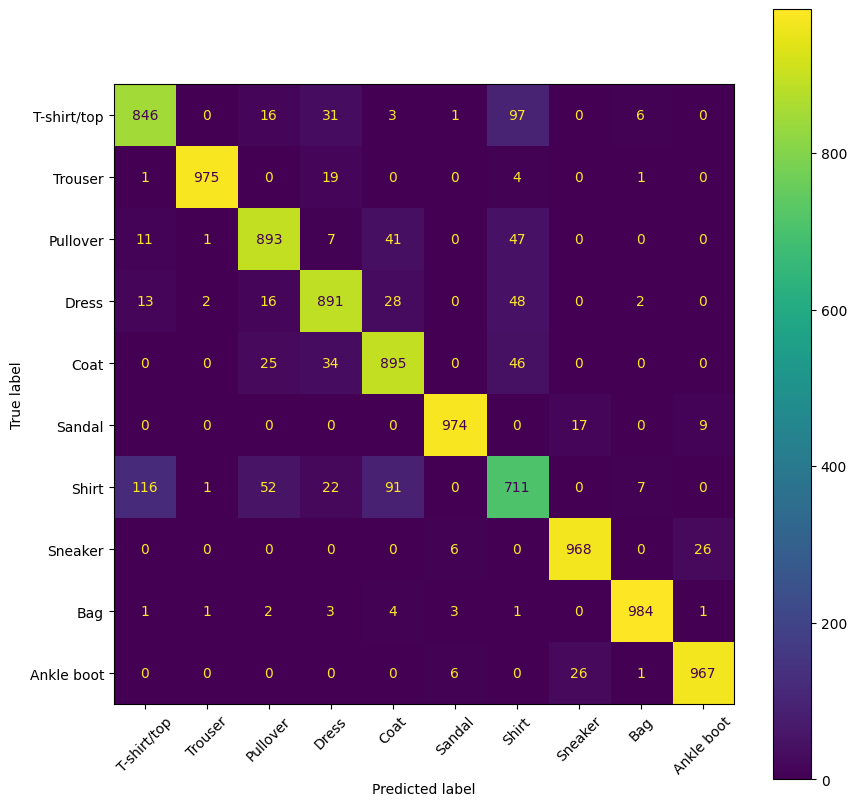

In [11]:
#예제10.9 VIT 모델 성능 평가
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

outputs = trainer.predict(subset_test_dataset)
print(outputs)

y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(axis=1)

labels = list(classes)
matrix = confusion_matrix(y_true, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=labels)
_, ax = plt.subplots(figsize=(10, 10))
display.plot(xticks_rotation=45, ax=ax)
plt.show()